# Avaliação Prática - Machine Learning 2 - Redes Neurais

**ARTHUR NUNES DOS SANTOS**  
**BRUNO FELIPE DE SOUZA ARAUJO**  
**NICOLE FAVA PIRES**

# Setup

In [3]:
# Importar bibliotecas utilizadas no notebook

import numpy as np                          # Computação numérica
import pandas as pd                         # Manipulação de dados
import matplotlib.pyplot as plt             # Geração de gráficos
import time                                 # Medição do tempo de treinamento

from sklearn.datasets import make_moons     # Geração de dados sintéticos para classificação
from sklearn.model_selection import train_test_split  # Separação entre treino e teste
from sklearn.preprocessing import StandardScaler      # Padronização das variáveis

import tensorflow as tf                     # Construção e treinamento de redes neurais
from tensorflow import keras                # API de alto nível do TensorFlow
from tensorflow.keras import layers         # Construção das camadas da rede

# Definir semente para tornar os experimentos reproduzíveis

np.random.seed(42)
tf.random.set_seed(42)

# Exibir gráficos no notebook

%matplotlib inline

In [5]:
# Carregar conjunto de dados utilizado nos experimentos

df = pd.read_csv("dataset_make_moons.csv")

# Exibir informações básicas sobre o conjunto de dados

print(f"Quantidade de instâncias: {df.shape[0]}")
print(f"Quantidade de variáveis de entrada: {df.shape[1] - 1}")
print(f"Quantidade de classes: {df['Classe'].nunique()}")

# Exibir as primeiras instâncias

display(df.head())

Quantidade de instâncias: 2000
Quantidade de variáveis de entrada: 2
Quantidade de classes: 2


,X1,X2,Classe
0,1.647039,0.308835,1
1,0.351039,0.965041,0
2,0.490616,-0.270617,1
3,-0.941262,0.034721,0
4,0.584584,-0.387536,1


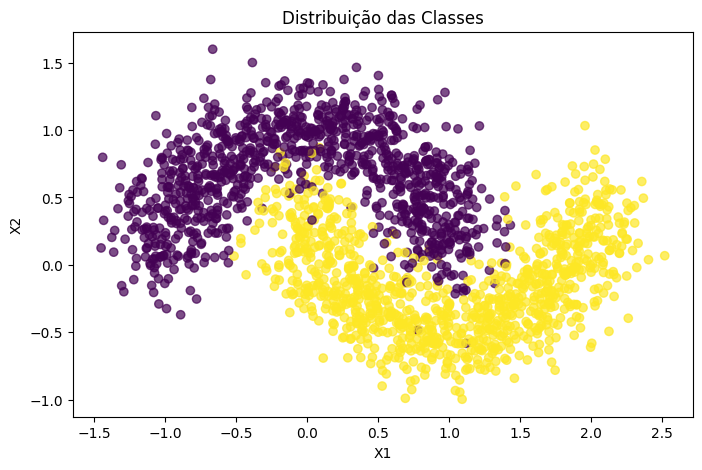

In [6]:
# Visualizar a distribuição das classes no espaço de entrada

plt.figure(figsize=(8, 5))

plt.scatter(
    df["X1"],
    df["X2"],
    c=df["Classe"],
    alpha=0.7
)

# Configurar o gráfico

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Distribuição das Classes")

plt.show()

## Orientações
Execute todas as células na ordem apresentada e responda às quatro questões com base nos resultados obtidos. Pequenas diferenças nos valores podem ocorrer entre as execuções.

# Split dos Dados

In [7]:
# Preparar os dados para treinamento dos modelos

# Separar variáveis de entrada e variável alvo
X = df[["X1", "X2"]].values
y = df["Classe"].values

# Dividir os dados entre treinamento e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,       # Utilizar 20% das instâncias para teste
    random_state=42,      # Garantir reprodutibilidade
    stratify=y            # Preservar a proporção das classes
)

# Padronizar as variáveis de entrada
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Exibir quantidade de instâncias
print(f"Treinamento: {len(X_train)} instâncias")
print(f"Teste: {len(X_test)} instâncias")

Treinamento: 1600 instâncias
Teste: 400 instâncias


# Camadas Ocultas
Teste fixado em 32 neurônios por camada

In [8]:
# Comparar redes neurais com diferentes quantidades de camadas ocultas

# Definir quantidades de camadas ocultas que serão testadas
quantidades_camadas = [1, 3, 5]

# Criar estrutura para armazenar os resultados
resultados_camadas = []

# Treinar uma rede para cada quantidade de camadas ocultas
for quantidade_camadas in quantidades_camadas:

    # Criar modelo sequencial
    model = keras.Sequential()

    # Criar camada de entrada
    model.add(layers.Input(shape=(2,)))

    # Adicionar a quantidade desejada de camadas ocultas (todas com 32 neurônios)
    for _ in range(quantidade_camadas):
        model.add(layers.Dense(32, activation="relu"))

    # Criar camada de saída para classificação binária
    model.add(layers.Dense(1, activation="sigmoid"))

    # Configurar o processo de treinamento
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Medir o tempo de treinamento
    inicio = time.time()

    model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=32,
        verbose=0
    )

    tempo = time.time() - inicio

    # Avaliar o modelo utilizando o conjunto de teste
    loss, accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    # Armazenar os resultados
    resultados_camadas.append({
        "Camadas Ocultas": quantidade_camadas,
        "Acurácia": accuracy,
        "Loss": loss,
        "Tempo (s)": tempo
    })

In [9]:
# Exibir resultados dos experimentos
df_resultados_camadas = pd.DataFrame(resultados_camadas)

display(df_resultados_camadas.round(4))

,Camadas Ocultas,Acurácia,Loss,Tempo (s)
0,1,0.9475,0.1287,2.4228
1,3,0.9600,0.1016,2.7354
2,5,0.9525,0.1062,2.8481


## Questão 1
Qual configuração apresentou a maior acurácia? Com base nos resultados obtidos, aumentar a quantidade de camadas ocultas sempre melhorou o desempenho? Explique.

**Resposta:** A configuração com 3 camadas ocultas apresentou a maior acurácia (0,9600), seguida de 5 camadas (0,9525) e 1 camada (0,9475). Não, aumentar a quantidade de camadas não melhorou o desempenho de forma constante: de 1 para 3 camadas houve ganho, mas de 3 para 5 camadas a acurácia caiu. Isso mostra que, para um problema simples como o make_moons, uma rede com profundidade excessiva não traz benefício adicional e pode até prejudicar o treinamento (maior dificuldade de otimização, sem necessidade real de mais capacidade).

# Número de Neurônios por Camada
Teste fixado em duas camadas ocultas

In [10]:
# Comparar redes neurais com diferentes quantidades de neurônios por camada

# Definir quantidades de neurônios que serão testadas
quantidades_neuronios = [8, 32, 64]

# Criar estrutura para armazenar os resultados
resultados_neuronios = []

# Treinar uma rede para cada quantidade de neurônios
for quantidade_neuronios in quantidades_neuronios:

    # Criar modelo sequencial
    model = keras.Sequential()

    # Criar camada de entrada
    model.add(layers.Input(shape=(2,)))

    # Criar DUAS camadas ocultas com a quantidade de neurônios definida
    model.add(layers.Dense(quantidade_neuronios, activation="relu"))
    model.add(layers.Dense(quantidade_neuronios, activation="relu"))

    # Criar camada de saída
    model.add(layers.Dense(1, activation="sigmoid"))

    # Configurar o processo de treinamento

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Treinar o modelo
    model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=32,
        verbose=0
    )

    # Avaliar o modelo
    loss, accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    # Armazenar os resultados
    resultados_neuronios.append({
        "Neurônios por Camada": quantidade_neuronios,
        "Acurácia": accuracy,
        "Loss": loss
    })

In [11]:
# Exibir resultados dos experimentos
df_resultados_neuronios = pd.DataFrame(resultados_neuronios)

display(df_resultados_neuronios.round(4))

,Neurônios por Camada,Acurácia,Loss
0,8,0.955,0.1032
1,32,0.960,0.0967
2,64,0.965,0.0959


## Questão 2
Compare as configurações com 8, 32 e 64 neurônios por camada. Qual apresentou a maior acurácia? O ganho de desempenho foi proporcional ao aumento da quantidade de neurônios? Justifique com os resultados.

**Resposta:** A configuração com 64 neurônios por camada apresentou a maior acurácia (0,965), seguida de 32 (0,960) e 8 (0,955). O ganho não foi proporcional ao aumento da quantidade de neurônios: de 8 para 32 neurônios (4x) a acurácia subiu apenas 0,005, e de 32 para 64 (2x) subiu outros 0,005. A rede já capturava bem o padrão dos dados mesmo com poucos neurônios, já que o problema é relativamente simples.

# Função de Ativação
Teste fixado em 2 camadas ocultas e 16 neurônios por camada

In [12]:
# Comparar redes neurais utilizando diferentes funções de ativação

# Definir funções de ativação que serão testadas
funcoes_ativacao = ["sigmoid", "tanh", "relu"]

# Criar estrutura para armazenar os resultados
resultados_ativacao = []

# Treinar uma rede para cada função de ativação
for funcao_ativacao in funcoes_ativacao:

    # Criar modelo sequencial
    model = keras.Sequential()

    # Criar camada de entrada
    model.add(layers.Input(shape=(2,)))

    # Criar duas camadas ocultas com 16 neurônios cada
    model.add(layers.Dense(16, activation=funcao_ativacao))
    model.add(layers.Dense(16, activation=funcao_ativacao))

    # Criar camada de saída para classificação binária
    model.add(layers.Dense(1, activation="sigmoid"))

    # Configurar o processo de treinamento
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Treinar o modelo
    model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=32,
        verbose=0
    )

    # Avaliar o modelo
    loss, accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    # Armazenar os resultados
    resultados_ativacao.append({
        "Função de Ativação": funcao_ativacao,
        "Acurácia": accuracy,
        "Loss": loss
    })

In [13]:

# Exibir resultados dos experimentos

df_resultados_ativacao = pd.DataFrame(resultados_ativacao)

display(df_resultados_ativacao.round(4))

,Função de Ativação,Acurácia,Loss
0,sigmoid,0.8850,0.2809
1,tanh,0.9525,0.0940
2,relu,0.9600,0.0964


## Questão 3
Qual função de ativação apresentou a maior acurácia neste experimento? Podemos concluir que essa função será sempre a melhor escolha para qualquer rede neural? Justifique.

**Resposta** A função ReLU apresentou a maior acurácia (0,9600), seguida de tanh (0,9525) e sigmoid, bem abaixo (0,8850). Não podemos concluir que ReLU será sempre a melhor escolha: o resultado depende do problema, da arquitetura e dos dados. A sigmoid, em particular, sofre com o problema do gradiente saturado em redes com mais camadas, o que explica seu desempenho inferior aqui, mas cada função tem cenários em que é mais adequada.

## Questão 4
Considerando o modelo utilizado nesta seção (Função de Ativação), identifique:
- a quantidade de camadas ocultas
- os neurônios por camada
- a funções de ativação das camadas ocultas
- a função de ativação da saída
- a quantidade total de parâmetros treináveis (mostre o cálculo).

**Resposta**
- Quantidade de camadas ocultas: 2
- Neurônios por camada: 16
- Função de ativação das camadas ocultas: testada em cada rodada (sigmoid, tanh ou relu)
- Função de ativação da saída: sigmoid
- Cálculo dos parâmetros treináveis:
  - Entrada → Camada 1 (2 → 16): pesos = 2×16 = 32, bias = 16 → 48
  - Camada 1 → Camada 2 (16 → 16): pesos = 16×16 = 256, bias = 16 → 272
  - Camada 2 → Saída (16 → 1): pesos = 16×1 = 16, bias = 1 → 17
  - Total = 48 + 272 + 17 = 337 parâmetros treináveis

# QUESTÕES GERAIS DE TEORIA

# Questão 5
Durante o treinamento de uma rede, determinado peso possui gradiente positivo. Um aluno afirma que devemos aumentar esse peso porque o gradiente indica a direção que reduz a perda. Outro afirma que o learning rate determina se o peso deve aumentar ou diminuir. Analise as duas afirmações.

**Resposta:** O primeiro aluno está errado: o gradiente aponta a direção de maior crescimento da perda, então, para reduzir a perda, o peso deve ser atualizado na direção oposta ao gradiente (subtraindo-o), ou seja, um gradiente positivo leva a uma diminuição do peso. O segundo aluno também está incompleto: o learning rate não determina a direção da atualização, apenas o tamanho do passo dado nessa direção — quem define a direção é o sinal do gradiente. A atualização correta é: `peso = peso - learning_rate * gradiente`.

# Questão 6
Considere duas redes idênticas treinadas sobre 10.000 instâncias durante 20 épocas. A Rede A utiliza batch_size = 100 e a Rede B utiliza batch_size = 500. Desconsiderando o último lote incompleto, quantas atualizações aproximadamente cada rede realizará durante todo o treinamento? Qual delas reavalia mais frequentemente a direção de atualização dos parâmetros?

**Resposta:** Rede A: 10.000 / 100 = 100 atualizações por época × 20 épocas = 2.000 atualizações. Rede B: 10.000 / 500 = 20 atualizações por época × 20 épocas = 400 atualizações. A Rede A (batch_size menor) reavalia mais frequentemente a direção de atualização dos parâmetros, pois realiza mais atualizações ao longo do treinamento, com lotes menores e mais ruidosos.

# Questão 7
Um aluno propõe utilizar Sigmoid em todas as camadas de uma rede profunda porque sua saída entre 0 e 1 parece facilitar a interpretação. Com base nas características das funções estudadas, explique por que essa justificativa não é suficiente para escolher a função das camadas ocultas e indique uma alternativa estudada em aula.

**Resposta:** A saída entre 0 e 1 não é motivo suficiente porque, nas camadas ocultas, o que importa é a capacidade da função de propagar bem o gradiente durante o backpropagation. A sigmoid satura para valores extremos (gradiente próximo de zero), causando o problema do vanishing gradien em redes profundas, além de sua saída não ser centrada em zero, o que prejudica a convergência. Uma alternativa estudada em aula é a ReLU, que evita a saturação para valores positivos e tem gradiente constante, tornando o treinamento mais eficiente em redes profundas.

# Questão 8
Uma rede será utilizada para três problemas diferentes: (A) prever o preço de um imóvel; (B) decidir se uma transação é fraude ou não; e (C) classificar uma imagem exclusivamente como cachorro, gato ou cavalo. Indique, para cada caso, uma configuração adequada da camada de saída em termos de quantidade de neurônios e função de ativação, justificando conforme o conteúdo estudado.

**Resposta:**
- **(A) Preço de imóvel (regressão):** 1 neurônio de saída, sem função de ativação (linear/identidade), pois o valor pode assumir qualquer número real positivo e não deve ser limitado a um intervalo.
- **(B) Fraude ou não (classificação binária):** 1 neurônio de saída com ativação sigmoid, que retorna uma probabilidade entre 0 e 1 de a transação ser fraude.
- **(C) Cachorro, gato ou cavalo (classificação multiclasse exclusiva):** 3 neurônios de saída com ativação softmax, que produz uma distribuição de probabilidade entre as classes, garantindo que a soma seja 1 e apenas uma classe seja escolhida.

# Questão 9
Durante o treinamento de uma rede neural, descreva a sequência que ocorre desde a entrada de um lote de dados até a atualização dos pesos e biases. Em sua resposta, explique o papel do forward propagation, da função de perda, do backpropagation, dos gradientes, do otimizador e do learning rate.

**Resposta:** O treinamento acontece de forma cíclica, lote a lote. Primeiro, um lote de instâncias entra na rede e ocorre o forward propagation: em cada neurônio das camadas ocultas é calculada a pré-ativação `z = Σ(wᵢxᵢ) + b`, sobre a qual se aplica a função de ativação, gerando a ativação que segue como entrada para a camada seguinte, até que a camada de saída produza a previsão ŷ.

Em seguida, a função de perda compara essa previsão ŷ com o valor esperado y e produz um único valor que mede o erro do modelo naquele lote (no nosso caso, binary cross-entropy). Esse valor global, porém, não diz como ajustar cada peso individualmente — ele apenas informa o tamanho do erro.

É aí que entra o backpropagation (retropropagação). Partindo da perda, ele percorre a rede no sentido inverso e, aplicando a regra da cadeia, calcula os gradientes: a derivada da perda em relação a cada peso e bias. Cada parâmetro recebe assim seu próprio gradiente, cujo sinal indica a direção local de aumento da perda e cuja magnitude indica a intensidade da sua influência sobre o erro.

Com os gradientes calculados, o otimizador decide como efetivamente atualizar os parâmetros, sempre caminhando na direção oposta ao gradiente para reduzir a perda — essa é a ideia do Gradient Descent. A taxa de aprendizado controla o tamanho do passo dado nessa direção: valores muito altos podem ultrapassar a região de mínimo e dificultar a convergência, enquanto valores muito baixos tornam o aprendizado lento.

Atualizados os pesos e biases, o ciclo recomeça com o próximo lote. Quando todos os lotes do conjunto de treinamento são processados, completa-se uma época, e o processo se repete pelo número de épocas definido.

# Questão 10
Um aluno afirma: “A função de perda informa diretamente quanto cada peso deve ser alterado. O backpropagation atualiza os pesos e o learning rate define a direção da atualização.” Identifique os erros dessa afirmação e descreva corretamente o papel de cada elemento no treinamento.

**Resposta:** A afirmação tem três erros. 1) A função de perda não informa diretamente quanto cada peso deve mudar — ela apenas mede o erro da rede; quem calcula o quanto cada peso contribuiu para esse erro é o backpropagation, via gradientes. 2) O backpropagation não atualiza os pesos, ele apenas calcula os gradientes; quem efetivamente atualiza os pesos é o otimizador. 3) O learning rate não define a direção da atualização (essa é dada pelo sinal do gradiente), apenas o tamanho do passo aplicado nessa direção.